In [1]:
#目标 找出的最佳新变量要同时满足 “方差最大”和“误差最小”
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA,TruncatedSVD
from sklearn.preprocessing import StandardScaler

import plotly.io as pio
import plotly.graph_objects as go
import plotly.express as px
from IPython.display import HTML

from scipy import  linalg as alg

pio.renderers.default = 'iframe' # or 'notebook' or 'colab' or 'jupyterlab'
def pxshow(arr,cols=None,rg=None):
    if cols is None:
        cols = ['col1','col2']
    if rg is None:
        rg = (np.max(arr),np.min(arr))

    df1 = pd.DataFrame(data=arr,columns=cols)
    # fig = px.line(df,x='col1',y='col2',markers=True)
    fig = px.scatter(df1,x=cols[0],y=cols[1])

    fig.update_layout(
        height=800,
        width=800,
        yaxis=dict(range=[rg[0],rg[1]]),
        xaxis=dict(range=[rg[0],rg[1]]),
        scene=dict(aspectratio=dict(x=1, y=1) ) 
    )
    return fig



In [2]:
#保留
#[1,0]向量固定不动，不断的旋转另一个向量的特征向量：不会产生复数特征向量，当两个向量接近与垂直是，变化一点点都导致特征向量的突变。

a = np.array([[1.,1.],[0.,0.]])
data = [[1,0]] #保存特征向量
arr = [[1,0]] #保存原数据
ev1d = [[0,0]]

txt = ['[1,0]']
seq = [0]
for i in np.linspace(0,2*np.pi,40):
    a[:,1] = np.array([[np.cos(np.pi/20),-np.sin(np.pi/20)],[np.sin(np.pi/20),np.cos(np.pi/20)]])@a[:,1]
    arr = np.vstack((arr,a[:,1]))
    ev1,ev2 = np.linalg.eig(a)
    data = np.vstack((data,ev2[:,1]))
    ev1d = np.vstack((ev1d,ev1))
    txt.append(str(a[:,1]))
    seq.append(len(seq))
    
df1 = pd.DataFrame(data=data,columns=['col1','col2'])
df1['txt']=txt
df1['seq'] = seq
df2 = pd.DataFrame(data=ev1d,columns=['col1','col2'])
df2['seq'] = seq

print(ev2[:,0])
# fig = px.line(df,x='col1',y='col2',markers=True)
fig1 = px.scatter(df1,x='col1',y='col2',hover_name='txt',text='seq',hover_data=['seq'])
fig1.update_traces(fig1.data[0],textposition='top center',textfont={'color': '#bebebe', 'size':8},name='ev2',showlegend=True)
fig2 = px.scatter(df2,x='col1',y='col2',text='seq',color=[3 for i in range(0,len(ev1d))])
fig2.update_traces(fig2.data[0],textposition='top center',textfont={'color': '#bebebe', 'size':8},name='ev1',showlegend=True)

fig = go.Figure(data=fig1.data + fig2.data)
fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-2,2]),
    xaxis=dict(range=[-2,2]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
    ,legend=dict(yanchor="top", y=1.1, xanchor="left", x=-0.12)
)

fig.show()



[1. 0.]


In [27]:
#保留
#修正特征向量后，将原数据和特征向量放入同一图形中()
for i in range(11):

df1 = pd.DataFrame(data=data,columns=['col1','col2'])
df1['txt']=txt
df1['seq'] = seq

# fig = px.line(df,x='col1',y='col2',markers=True)
fig1 = px.scatter(df1,x='col1',y='col2',hover_name='txt',text='seq',hover_data=['seq'])
fig1.update_traces(fig1.data[0],textposition='top center',textfont={'color': '#bebebe', 'size':8},showlegend=True,name='data')

df2 = pd.DataFrame(data=arr,columns=['col1','col2'])
df2['seq'] = seq
# fig2 = px.scatter(df2,x='col1',y='col2',text='seq',hover_data=['seq'])
# fig2.update_traces(fig2.data[0],textposition='top center',textfont={'color': '#bebebe', 'size':8},showlegend=True,name='arr')
# fig1.update_traces(fig1.data[0],textposition='top center',textfont={'color': '#bebebe', 'size':8})
fig = go.Figure(data=fig1.data)  #+fig2.data
fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-2,2]),
    xaxis=dict(range=[-2,2]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)
fig.add_traces(go.Scatter(x=df2['col1'],y=df2['col2'],name='arr',mode='markers+text',text=df2['seq'],
                          textposition='top center',textfont={'color': '#bebebe', 'size':8}))


fig.show()

In [45]:
t = np.array([[np.cos(np.pi/3),-np.sin(np.pi/3)],[np.sin(np.pi/3),np.cos(np.pi/3)]])@np.array([1,0])
t = t[:,None]
t = np.hstack((np.array([1,0]).reshape(-1,1),t))
print(t)
np.linalg.eig(t)
# arr


[[1.        0.5      ]
 [0.        0.8660254]]


(array([1.       , 0.8660254]),
 array([[ 1.        , -0.96592583],
        [ 0.        ,  0.25881905]]))

In [28]:
#[1,0]向量固定不动，另一个向量加倍，然后不断的旋转，

a = np.array([[1.,2],[0.,0.]])
data = [[1,0]] #保存特征向量
arr = [[1,0]] #保存原数据
ev1d = [[0,0]]

txt = ['[1,0]']
seq = [0]
for i in np.linspace(0,2*np.pi,40):
    a[:,1] = np.array([[np.cos(np.pi/20),-np.sin(np.pi/20)],[np.sin(np.pi/20),np.cos(np.pi/20)]])@a[:,1]
    arr = np.vstack((arr,a[:,1]))
    ev1,ev2 = np.linalg.eig(a)
    data = np.vstack((data,ev2[:,1]))
    ev1d = np.vstack((ev1d,ev1))
    txt.append(str(a[:,1]))
    seq.append(len(seq))
    
df1 = pd.DataFrame(data=data,columns=['col1','col2'])
df1['txt']=txt
df1['seq'] = seq
print(ev2[:,0])
# fig = px.line(df,x='col1',y='col2',markers=True)
fig = px.scatter(df1,x='col1',y='col2',hover_name='txt',text='seq',hover_data=['seq'])
fig.update_traces(fig.data[0],textposition='top center',textfont={'color': '#bebebe', 'size':8})
fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-2,2]),
    xaxis=dict(range=[-2,2]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)

fig.show()

[1. 0.]


In [32]:
#一个向量是[1，0]，另一个向量成30度的夹角，然后向量的长度不断增加
a = np.array([[1.,1],[0.,0.]])
a[:,1] = np.array([[np.cos(np.pi/3),-np.sin(np.pi/3)],[np.sin(np.pi/3),np.cos(np.pi/3)]])@a[:,1]
data = [np.linalg.eig(a)[1][:,1]] #保存特征向量
arr = [a[:,1]] #保存原数据
ev1d = [np.linalg.eig(a)[0]]

txt = [str(a[:,1])]
seq = [0]
for i in range(1,81):
    a[:,1] = a[:,1]*1.1
    arr = np.vstack((arr,a[:,1]))
    ev1,ev2 = np.linalg.eig(a)
    data = np.vstack((data,ev2[:,1]))
    ev1d = np.vstack((ev1d,ev1))
    txt.append(str(a[:,1]))
    seq.append(len(seq))
    
df1 = pd.DataFrame(data=data,columns=['col1','col2'])
df1['txt']=txt
df1['seq'] = seq

# fig = px.line(df,x='col1',y='col2',markers=True)
fig = px.scatter(df1,x='col1',y='col2',hover_name='txt',text='seq',hover_data=['seq'])
fig.update_traces(fig.data[0],textposition='top center',textfont={'color': '#bebebe', 'size':8})
fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-2,2]),
    xaxis=dict(range=[-2,2]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)
t = arr[0,:]/np.linalg.norm(arr[0,:])
fig.add_traces(go.Scatter(x=[0,arr[0,0]],y=[0,arr[0,1]]))

fig.show()

In [46]:
#保持两个向量始终是30度，不断的旋转这个矩阵，查看对应的特征向量
a = np.array([[1.,1.],[0.,0.]])
b = np.array([[np.cos(np.pi/6),-np.sin(np.pi/6)],[np.sin(np.pi/6),np.cos(np.pi/6)]])@a[:,1]
a[:,1] = b


txt1 = [] #复数的特征向量
txt2 = [] #无
seq = [0]
data = [[0,a]] #存储原始的向量
ev1,ev2 = np.linalg.eig(a)
data1 = (ev2[:,0])[None,:]  #第一个特征向量
data2 =  (ev2[:,1])[None,:] #第二个特征向量


for i in range(1,41):
    a = np.array([[np.cos(np.pi/20),-np.sin(np.pi/20)],[np.sin(np.pi/20),np.cos(np.pi/20)]])@a
    ev1,ev2 = np.linalg.eig(a)
    data.append([i,a])
    if ev2.dtype == 'complex':
        txt1.append([i,a,ev2])
#         txt2.append(ev2[:,1])
    else:
        data1 = np.vstack((data1,ev2[:,0]))
        data2 = np.vstack((data2,ev2[:,1]))
        seq.append(i)
df1 = pd.DataFrame(data=data1,columns=['col1','col2'])
# df1['txt']=txt
df1['seq'] = seq
df1['color'] = 1
df2 = pd.DataFrame(data=data2,columns=['col1','col2'])
# df1['txt']=txt
df2['seq'] = seq
df2['color'] = 2

# fig = px.line(df,x='col1',y='col2',markers=True)
fig1 = px.scatter(df1,x='col1',y='col2',hover_data=['seq'],text='seq',color='color')
fig2 = px.scatter(df2,x='col1',y='col2',hover_data=['seq'],text='seq',color='color')
fig = go.Figure(data = fig1.data+fig2.data)
fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-2,2]),
    xaxis=dict(range=[-2,2]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)
fig.update_traces(textposition='top center',textfont={'color': '#bebebe', 'size':8})

fig.show()

In [24]:
data[7:10]

[[7,
  array([[ 0.4539905 , -0.05233596],
         [ 0.89100652,  0.99862953]])],
 [8,
  array([[ 0.30901699, -0.20791169],
         [ 0.95105652,  0.9781476 ]])],
 [9,
  array([[ 0.15643447, -0.35836795],
         [ 0.98768834,  0.93358043]])]]

In [25]:
t = data[8][1]
alg.qr(t)

(array([[-0.30901699, -0.95105652],
        [-0.95105652,  0.30901699]]),
 array([[-1.       , -0.8660254],
        [ 0.       ,  0.5      ]]))

In [35]:
t = txt1[8][2]
t@t.T


array([[ 1.2570529 +0.00000000e+00j, -0.57735027+1.73535181e-17j],
       [-0.57735027+1.73535181e-17j, -0.21260612+1.34924375e-17j]])

In [21]:
#原完整data的图像（原矩阵）
arr1 = np.empty(shape=(0,2))
arr2 = np.empty(shape=(0,2))
seq = []
for i in data:
    arr1 = np.vstack((arr1,i[1][:,0]))
    arr2 = np.vstack((arr2,i[1][:,1]))
    
df1 = pd.DataFrame(data=arr1,columns=['col1','col2'])
# df1['txt']=txt
df1['seq'] = range(0,len(arr1))
df1['color'] = 1
df2 = pd.DataFrame(data=arr2,columns=['col1','col2'])
# df1['txt']=txt
df2['seq'] = range(0,len(arr2))
df2['color'] = 2

# fig = px.line(df,x='col1',y='col2',markers=True)
fig1 = px.scatter(df1,x='col1',y='col2',hover_data=['seq'],text='seq',color='color')
fig2 = px.scatter(df2,x='col1',y='col2',hover_data=['seq'],text='seq',color='color')
fig = go.Figure(data = fig1.data+fig2.data)
fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-2,2]),
    xaxis=dict(range=[-2,2]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)
fig.update_traces(textposition='top center',textfont={'color': '#bebebe', 'size':8})

fig.show()

In [15]:
c = np.empty(shape=(0,2))
a = np.array([1,1])
b = np.array([2,3])
d = np.vstack((c,a))
len(d)


1

In [14]:
np.empty(shape=(0,3))
np.array([[]]*3).T

array([], shape=(3, 0), dtype=float64)

In [5]:
data

[[0,
  array([[1.       , 0.8660254],
         [0.       , 0.5      ]])],
 [1,
  array([[0.98768834, 0.77714596],
         [0.15643447, 0.62932039]])],
 [2,
  array([[0.95105652, 0.66913061],
         [0.30901699, 0.74314483]])],
 [3,
  array([[0.89100652, 0.54463904],
         [0.4539905 , 0.83867057]])],
 [4,
  array([[0.80901699, 0.40673664],
         [0.58778525, 0.91354546]])],
 [5,
  array([[0.70710678, 0.25881905],
         [0.70710678, 0.96592583]])],
 [6,
  array([[0.58778525, 0.10452846],
         [0.80901699, 0.9945219 ]])],
 [7,
  array([[ 0.4539905 , -0.05233596],
         [ 0.89100652,  0.99862953]])],
 [8,
  array([[ 0.30901699, -0.20791169],
         [ 0.95105652,  0.9781476 ]])],
 [9,
  array([[ 0.15643447, -0.35836795],
         [ 0.98768834,  0.93358043]])],
 [10,
  array([[-1.76255955e-17, -5.00000000e-01],
         [ 1.00000000e+00,  8.66025404e-01]])],
 [11,
  array([[-0.15643447, -0.62932039],
         [ 0.98768834,  0.77714596]])],
 [12,
  array([[-0.30901699, -

In [65]:
a = np.array([[1,1,1],[1,2,3],[2,3,4]])
# a = np.array([[1,1,-1],[1,2,1],[2,3,2]])
ev1,ev2 = np.linalg.eig(a)
print(alg.orth(a))
alg.qr(a)


[[-0.24604077  0.7785439 ]
 [-0.55121841 -0.60234951]
 [-0.79725918  0.17619439]]


(array([[-4.08248290e-01,  7.07106781e-01, -5.77350269e-01],
        [-4.08248290e-01, -7.07106781e-01, -5.77350269e-01],
        [-8.16496581e-01,  5.55111512e-16,  5.77350269e-01]]),
 array([[-2.44948974e+00, -3.67423461e+00, -4.89897949e+00],
        [ 0.00000000e+00, -7.07106781e-01, -1.41421356e+00],
        [ 0.00000000e+00,  0.00000000e+00,  5.55111512e-16]]))

In [11]:
np.mean(data,axis=0)
t = data - np.mean(data,axis=0)
np.sum(t*t,axis=0)

array([3.9663441, 3.9663441])

In [2]:
#创建一个圆的数据
a = np.linspace(0,np.pi/2,40)
x = np.cos(a)
y = np.sin(a)
print(x@y)
data = np.concatenate((x.reshape(-1,1),y.reshape(-1,1)),axis=1) 
# data = (np.array([[np.cos(np.pi/4),-np.sin(np.pi/4)],[np.sin(np.pi/4),np.cos(np.pi/4)]]) @(data.T)).T
df1 = pd.DataFrame(data=data,columns=['col1','col2'])
# fig = px.line(df,x='col1',y='col2',markers=True)
fig = px.scatter(df1,x='col1',y='col2')

fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-1.2,1.2]),
    xaxis=dict(range=[-1.2,1.2]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)

fig.show()
print(data[:,0]@data[:,1])




12.407372030262563


12.407372030262561


In [39]:
d2 = data - np.mean(data,axis=0)
df1 = pd.DataFrame(data=d2,columns=['col1','col2'])
# fig = px.line(df,x='col1',y='col2',markers=True)
fig = px.scatter(df1,x='col1',y='col2')

fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-1.2,1.2]),
    xaxis=dict(range=[-1.2,1.2]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)

fig.show()
print(data[:,0]@data[:,1])

12.407372030262561


In [9]:
#查看特征向量的特点
a = np.linspace(0,np.pi/2,40)
x = np.cos(a)
y = np.sin(a)
data = np.concatenate((x.reshape(-1,1),y.reshape(-1,1)),axis=1) 

#根据上面1/4 圆 形成点的协方差矩阵的特点：
# d2 = data - np.mean(data,axis=0)
# d2 = d2.T@d2
#将圆弧旋转30度
d3 = np.array([[np.cos(np.pi/6),-np.sin(np.pi/6)],[np.sin(np.pi/6),np.cos(np.pi/6)]])@(data.T)
d3 = d3.T
d2 = d3.T@d3

#将协方差矩阵分解成R@V@inv(R)
ev1,ev2 = np.linalg.eig(d2)
print(d2)
print(ev1)
print(ev2)

print(ev2@np.diag(ev1)@ev2.T)

print(d2@np.linalg.inv(ev2)@np.linalg.inv(np.diag(np.sqrt(ev1) ) )@ev2 )

print(d2@ev2@np.linalg.inv(np.diag(ev1 ) )@np.linalg.inv(ev2) )
d = d2@ev2@np.linalg.inv(np.diag(np.sqrt(ev1) )) #
print(d.T@d)
pxshow(data,rg=(-1.2,1.2)).show()



[[ 9.25490063  6.20368602]
 [ 6.20368602 30.74509937]]
[ 7.59262797 32.40737203]
[[-0.96592583 -0.25881905]
 [ 0.25881905 -0.96592583]]
[[ 9.25490063  6.20368602]
 [ 6.20368602 30.74509937]]
[[3.53305901 1.6008184 ]
 [3.61286053 6.07681374]]
[[ 1.00000000e+00  1.60717152e-16]
 [-1.09139169e-16  1.00000000e+00]]
[[ 7.59262797e+00 -4.23125127e-15]
 [-4.23125127e-15  3.24073720e+01]]


AttributeError: 'NoneType' object has no attribute 'show'

In [13]:
b = np.ones((len(data),1))
x.ravel()
yh = [i*w[0,0]+w[1,0] for i in x.ravel()]
yh

# data2[:,0].reshape((-1,1))

# data4 = np.hstack((data[:,0].reshape((-1,1)),b))
# w = np.linalg.inv(data4.T@data4)@data4.T@(data4[:,1].reshape((-1,1)) )
# w

[0.5953913717530328,
 0.5968743105877394,
 0.6013207217596461,
 0.6087233931735727,
 0.619070317669415,
 0.6323447124978032,
 0.6485250465417836,
 0.6675850752403669,
 0.689493883157305,
 0.7142159341260383,
 0.7417111288894911,
 0.7719348701412105,
 0.8048381348623628,
 0.8403675538372468,
 0.87846549821836,
 0.9190701730005966,
 0.9621157172529746,
 1.007532310945305,
 1.0552462881965365,
 1.1051802567610847,
 1.1572532235593356,
 1.2113807260487195,
 1.2674749692222618,
 1.3254449680124056,
 1.3851966948691257,
 1.4466332322729567,
 1.5096549299355644,
 1.574159566432879,
 1.6400425150086169,
 1.7071969132792635,
 1.7755138365652496,
 1.84488247456718,
 1.915190311100544,
 1.9863233065973789,
 2.0581660830788646,
 2.1306021112988294,
 2.2035138997546126,
 2.27678318525871,
 2.3502911247620992,
 2.4239184881180966]

In [64]:
#查看特征向量的特点(保留1)
a = np.linspace(0,np.pi/2,40)
x = np.cos(a)
y = np.sin(a)
y2 = 2*y
data = np.concatenate((x.reshape(-1,1),y.reshape(-1,1)),axis=1) 
data4 = np.concatenate((x.reshape(-1,1),y2.reshape(-1,1)),axis=1) 
#根据上面1/4 圆 形成点的协方差矩阵的特点：
# d2 = data - np.mean(data,axis=0)
# d2 = d2.T@d2
#将圆弧旋转30度
# d3 = np.array([[np.cos(np.pi/6),-np.sin(np.pi/6)],[np.sin(np.pi/6),np.cos(np.pi/6)]])@(data.T)
# d3 = d3.T


#将协方差矩阵分解成R@V@inv(R)
ev1,ev2 = np.linalg.eig(data.T@data4)  
# pxshow(data4,rg=(-2.2,2.2)).show()

# print(ev2@np.diag(ev1)@ev2.T)
# print(data4@np.linalg.inv(ev2)@np.linalg.inv(np.diag(np.sqrt(ev1) ) )@ev2 )
# print(data4@ev2@np.linalg.inv(np.diag(ev1 ) )@np.linalg.inv(ev2) )
# d = d4@ev2@np.linalg.inv(np.diag(np.sqrt(ev1) )) #

 
e1,e2 = np.linalg.eig(data4.T@data4)

#对data4进行线性回归

t = np.ones((len(data4),1))
x = x.reshape(-1,1)
y = y.reshape(-1,1)
y2 = y2.reshape(-1,1)

data5 = np.hstack((x,t))
w = np.linalg.inv(data5.T@data5)@data5.T@y2

yh = np.array([i*w[0,0]+w[1,0] for i in x.ravel()])

data5 = np.hstack((x,yh.reshape(-1,1)))

#找出data4的特征向量的情况



df1 = pd.DataFrame(data=data,columns=['col1','col2'])
fig1 = px.scatter(df1,x='col1',y='col2')
fig1.update_traces(fig1.data[0],name='圆data',showlegend=True)

df2 = pd.DataFrame(data=data4,columns=['col1','col2'])
fig2 = px.scatter(df2,x='col1',y='col2')
fig2.update_traces(fig2.data[0],name='椭圆data4',showlegend=True,marker=dict(color=['red' for i in range(len(data4))]))

df3 = pd.DataFrame(data=data5,columns=['col1','col2'])
fig3 =px.scatter(df3,x='col1',y='col2')
fig3.update_traces(fig3.data[0],name='回归线data5',showlegend=True,marker=dict(color=['green' for i in range(len(data5))]))

# 画出特征向量的指向
fig = go.Figure(data=fig1.data + fig2.data+fig3.data)

fig.add_traces(go.Scatter(x=[0,e2[0,0]],y=[0,e2[0,1]],name='data4v1'))
fig.add_traces(go.Scatter(x=[0,e2[1,0]],y=[0,e2[1,1]],name='data4v2'))
# fig.add_traces(go.Scatter(x=[0,ev2[0,0]],y=[0,ev2[1,0]],name='v1'))
# fig.add_traces(go.Scatter(x=[0,ev2[0,1]],y=[0,ev2[1,1]],name='v2'))

#将data5旋转e2 特性向量
# data5_2 = (e2@(data4.T)).T
data4_2 = data4@e2 # @np.linalg.inv(np.diag(e1 ) )  #@np.linalg.inv(e2)
print('data4的协方差矩阵:\n',data4.T@data4)
print('data4旋转后的协方差矩阵：\n',data4_2.T@data4_2)
print('data4的特征向量：\n',e1,'\n',e2)
print('data4特征向量的还原',e2@np.diag)
fig.add_traces(go.Scatter(x=data4_2[:,0],y=data4_2[:,1],name='data4_2',mode='markers',
                          marker=dict(color=['red' for i in range(len(data4_2))])))
data5_2 = data5@e2
fig.add_traces(go.Scatter(x=data5_2[:,0],y=data5_2[:,1],name='data5_2',mode='markers',
                         marker=dict(color=['green' for i in range(len(data5_2))])))
# fig.add_traces(go.Scatter(x=[0,1],y=[0,1 * w[0,0]],name='data5_3'))

fig.update_layout(
    height=850,
    width=850,
    yaxis=dict(range=[-3,3]),
    xaxis=dict(range=[-3,3]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)

fig.show()


# fig = go.Figure(data=pxshow(data2,rg=(-2.5,2.5)).data + pxshow(data,rg=(-2.5,2.5)).data)
# fig.show()



data4的协方差矩阵:
 [[20.         24.81474406]
 [24.81474406 80.        ]]
data4旋转后的协方差矩阵：
 [[ 1.10670895e+01 -2.23073031e-15]
 [-2.23073031e-15  8.89329105e+01]]
data4的特征向量：
 [11.06708946 88.93291054] 
 [[-0.94089221 -0.33870613]
 [ 0.33870613 -0.94089221]]


In [75]:

print(data4.T@data4)
ev1,ev2 = np.linalg.eig(data4.T@data4)
print(ev1,ev2)
data4_2 = data4@ev2
print(data4_2.T@data4_2)
np.sum(data4_2*data4_2,axis=0)

[[20.         24.81474406]
 [24.81474406 80.        ]]
[11.06708946 88.93291054] [[-0.94089221 -0.33870613]
 [ 0.33870613 -0.94089221]]
[[ 1.10670895e+01 -2.23073031e-15]
 [-2.23073031e-15  8.89329105e+01]]


array([11.06708946, 88.93291054])

In [46]:
A = np.linspace(0, 2, 20)
B = np.sin(A)
C = np.cos(A) * 2
t1 = np.array([[A.T@A,A.T@C],[B.T@A,B.T@C]])
print(t1)
print(np.linalg.eig(t1))
t2 = np.hstack((A[:,None],B[:,None],C[:,None]))
print('\n')
print(t2.T@t)
print(np.linalg.eig(t2.T@t2))


[[27.36842105  6.75744913]
 [17.45509142  7.44737321]]
(array([32.14438006,  2.6714142 ]), array([[ 0.8166264 , -0.26391348],
       [ 0.57716664,  0.96454636]]))


[[27.36842105 17.45509142  6.75744913]
 [17.45509142 11.7041733   7.44737321]
 [ 6.75744913  7.44737321 33.18330678]]
(array([ 0.18670931, 46.07810957, 25.99108226]), array([[ 0.5235334 , -0.64858993, -0.55248881],
       [-0.84784005, -0.46063292, -0.26264914],
       [ 0.08414295, -0.60592774,  0.79105723]]))


In [48]:
print(t1[0,1]*t1[1,0],'\n',t1[0,1]* t[1,1],'\n',t1[1,0]*t1[1,1])

117.95189239413196 
 0.7099975700082853 
 129.9945801646358


In [40]:
fig1 = pxshow(np.hstack((A[:,None],B[:,None])),rg=[-5,5])
fig1.update_traces(fig1.data[0],name='AB',showlegend=True)
fig1.add_traces(go.Scatter(x=A,y=C,name='AC',mode='markers'))
# fig1.add_traces(go.Scatter(x=A,y=B,name='AB'))
fig1.add_traces(go.Scatter(x=B,y=C,name='BC',mode='markers'))
fig1.show()

In [42]:
fig1.data

(Scatter({
     'hovertemplate': 'col1=%{x}<br>col2=%{y}<extra></extra>',
     'legendgroup': '',
     'marker': {'color': '#636efa', 'symbol': 'circle'},
     'mode': 'markers',
     'name': 'AB',
     'orientation': 'v',
     'showlegend': True,
     'x': array([0.        , 0.10526316, 0.21052632, 0.31578947, 0.42105263, 0.52631579,
                 0.63157895, 0.73684211, 0.84210526, 0.94736842, 1.05263158, 1.15789474,
                 1.26315789, 1.36842105, 1.47368421, 1.57894737, 1.68421053, 1.78947368,
                 1.89473684, 2.        ]),
     'xaxis': 'x',
     'y': array([0.        , 0.10506887, 0.20897462, 0.310567  , 0.40872137, 0.50235115,
                 0.59041986, 0.67195255, 0.74604665, 0.81188195, 0.86872962, 0.91596036,
                 0.95305133, 0.97959192, 0.99528832, 0.99996678, 0.9935755 , 0.97618524,
                 0.9479885 , 0.90929743]),
     'yaxis': 'y'
 }),
 Scatter({
     'mode': 'markers',
     'name': 'AC',
     'x': array([0.        , 0.10526

In [50]:
#查看协方差矩阵的特征向量，然后根据特征向量进行旋转，然后旋转后的向量 就是稳定的了。(保留2)
ev1,ev2 = np.linalg.eig(data4.T@data4)
fig = pxshow(np.array([[0,0],[ev2[0,0],ev2[0,1]]]),rg=[-2.2,2.2])
fig.update_traces(fig.data[0],name='ev2',showlegend=True,mode="lines+markers")
fig.add_traces(go.Scatter(x=[0,ev2[1,0]],y=[0,ev2[1,1]],name='ev2'))
fig.add_traces(go.Scatter(x=data4[:,0],y=data4[:,1],name='data4'))


data4_2 = data4@ev2
fig.add_traces(go.Scatter(x=data4_2[:,0],y=data4_2[:,1],name='data4_2'))
e421,e422 = np.linalg.eig(data4_2.T@data4_2)
fig.add_traces(go.Scatter(x=[0,e422[0,0]],y=[0,e422[0,1]],name='e422'))
fig.add_traces(go.Scatter(x=[0,e422[1,0]],y=[0,e422[1,1]],name='e422'))

data4_3 = data4_2@e422
fig.add_traces(go.Scatter(x=data4_3[:,0],y=data4_3[:,1],name='data4_3'))
e431,e432 = np.linalg.eig(data4_3.T@data4_3)
fig.add_traces(go.Scatter(x=[0,e432[0,0]],y=[0,e432[0,1]],name='e432'))
fig.add_traces(go.Scatter(x=[0,e432[1,0]],y=[0,e432[1,1]],name='e432'))


fig.show()

# t2 = (ev3@(data4.T)).T
# print(np.linalg.eig(data4.T@data4))
# print(np.linalg.eig((t2.T)@t2))




In [68]:
#将特征向量逆时针旋转90度，查看是否满足特征向量和特征值的特点。
#r = np.array([[np.cos(-np.pi*156.00415/400.0),-np.sin(-np.pi*156.00415/400.0)],[np.sin(-np.pi*156.00415/400.0),np.cos(-np.pi*156.00415/400.0)]])
ev1,ev2 = np.linalg.eig(data4.T@data4)
r = np.array([[0,-1],[1,0]]) #逆时针旋转90度
ev3 = r@(ev2.T)  #data4的特征向量逆时针旋转了90度

data4_3 = (ev3@(data4.T)).T
fig = pxshow(data4_3,rg=[-2.2,2.2])
fig.update_traces(fig.data[0],name='data4_3',showlegend=True,mode="markers",
                 marker=dict(color=['red' for i in range(len(data4))]))

fig.add_trace(go.Scatter(x=data4[:,0],y=data4[:,1],name='data4',mode='markers',
                          marker=dict(color=['red' for i in range(len(data4))])))
data4_2 = data4@ev2
fig.add_trace(go.Scatter(x=data4_2[:,0],y=data4_2[:,1],name='data4_2',mode='markers',
                          marker=dict(color=['red' for i in range(len(data4_2))])))

fig.add_traces(go.Scatter(x=[0,ev2[0,0]],y=[0,ev2[0,1]],name='data4v1'))
fig.add_traces(go.Scatter(x=[0,ev2[1,0]],y=[0,ev2[1,1]],name='data4v2'))

fig.add_traces(go.Scatter(x=[0,ev3[0,0]],y=[0,ev3[1,0]],name='data4v21'))
fig.add_traces(go.Scatter(x=[0,ev3[0,1]],y=[0,ev3[1,1]],name='data4v22'))

#对data4_3再逆时针旋转90度:
ev4 = r@ev3
data4_4 = (ev4@(data4.T)).T
fig.add_trace(go.Scatter(x=data4_4[:,0],y=data4_4[:,1],name='data4_4',mode='markers',
                          marker=dict(color=['red' for i in range(len(data4_4))])))

fig.show()


In [70]:
#ev3是否也是 data4的特征向量
print(ev2)
print(ev3)





[[-0.94089221 -0.33870613]
 [ 0.33870613 -0.94089221]]
[[ 0.33870613  0.94089221]
 [-0.94089221  0.33870613]]


In [67]:
d1 = np.array([[1,1,2],[-1,1,1]])
e1,e2 = np.linalg.eig(d1@d1.T)
d1.T@e2

array([[ 0.4472136 , -1.34164079],
       [ 1.34164079,  0.4472136 ],
       [ 2.23606798,  0.        ]])

In [74]:
# t = np.array([[np.cos(-np.pi*3/8),-np.sin(-np.pi*3/8)],[np.sin(-np.pi*3/8),np.cos(-np.pi*3/8)]])@(data4.T)
t = data4.T
for i in range(200):
    t = np.array([[np.cos(-np.pi/400),-np.sin(-np.pi/400)],[np.sin(-np.pi/400),np.cos(-np.pi/400)]])@t
    print(i,':',t@(t.T))


pxshow(t.T,rg=[-2.2,2.2]).show()

# print(t@t.T)
# print(np.linalg.eig(t@t.T))

0 : [[20.39347408 25.28290225]
 [25.28290225 79.60652592]]
1 : [[20.79425314 25.74482225]
 [25.74482225 79.20574686]]
2 : [[21.20223827 26.20039011]
 [26.20039011 78.79776173]]
3 : [[21.61732882 26.64949342]
 [26.64949342 78.38267118]]
4 : [[22.03942237 27.09202136]
 [27.09202136 77.96057763]]
5 : [[22.46841477 27.52786475]
 [27.52786475 77.53158523]]
6 : [[22.90420018 27.95691605]
 [27.95691605 77.09579982]]
7 : [[23.34667107 28.3790694 ]
 [28.3790694  76.65332893]]
8 : [[23.79571828 28.79422064]
 [28.79422064 76.20428172]]
9 : [[24.25123099 29.20226733]
 [29.20226733 75.74876901]]
10 : [[24.71309684 29.60310881]
 [29.60310881 75.28690316]]
11 : [[25.18120184 29.99664616]
 [29.99664616 74.81879816]]
12 : [[25.65543051 30.38278228]
 [30.38278228 74.34456949]]
13 : [[26.13566585 30.76142191]
 [30.76142191 73.86433415]]
14 : [[26.62178934 31.13247162]
 [31.13247162 73.37821066]]
15 : [[27.11368107 31.49583986]
 [31.49583986 72.88631893]]
16 : [[27.61121965 31.85143697]
 [31.85143697 72.3

In [55]:
t = data4.T@data4
t = t/t[1,0]

# fig.add_traces(go.Scatter(x=[0,t[0,0]],y=[0,t[1,0]],name='t'))
# fig.add_traces(go.Scatter(x=[0,t[0,1]],y=[0,t[1,1]],name='t2'))
#插入回归线旋转后的情况。
t=data5@e2
fig.add_traces(go.Scatter(x=t[:,0],y=t[:,1],name='回归线旋转'))


fig.show()

In [53]:
t

array([[0.80597245, 1.        ],
       [1.        , 3.22388979]])

In [11]:
#
print(ev1)
d2 = data@ev2
df1 = pd.DataFrame(d2,columns=['col1','col2'])
fig = px.scatter(df1,x='col1',y='col2')

fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-1.2,1.2]),
    xaxis=dict(range=[-1.2,1.2]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)
fig.show()


[32.40737203  7.59262797]


In [49]:
#测试任意两个向量的旋转因素和拉伸的因素，就是想直接分解成旋转和拉伸两个矩阵组，但是没有成功。
a = np.array([2,1])
a1 = a.reshape(-1,1)

b = np.array([1,3])
b1 = b.reshape(-1,1)
pb = ((a1@a1.T)/(a1.T@a1))@b1


c = b1 - pb

arr1 = np.hstack((a1,b1))
a2 = pb + a1

ev1 = np.diag(np.array([np.linalg.norm(a2),np.linalg.norm(c)]))

arr2 = np.hstack((a2/np.linalg.norm(a2),c/np.linalg.norm(c)))

x = np.array([-1,-3]).reshape(-1,1)
ev1,ev2 = np.linalg.eig(arr1)
data = np.vstack((x.T,(ev2.T@x).T ))  #x原向量和旋转后的向量

data = np.vstack((data,np.diag(ev1)@data[1,:] )) #加入伸缩后的向量

data = np.vstack((data,ev2@data[2,:] ))  #第二次旋转

data = np.vstack((data,(arr1@x).T )) #原矩阵与向量相乘

df1 = pd.DataFrame(data=data,columns=['col1','col2'])
df1['txt'] = ['1','2','3','4','5']
# fig = px.line(df,x='col1',y='col2',markers=True)
fig = px.scatter(df1,x='col1',y='col2',text='txt')

fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-20,20]),
    xaxis=dict(range=[-20,20]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)

fig.show()

data









array([[ -1.        ,  -3.        ],
       [ -0.72654253,   3.07768354],
       [ -1.00405708,  11.13516364],
       [ -5.        , -10.        ],
       [ -5.        , -10.        ]])

In [63]:
P,L,U = alg.lu(arr1)
D = np.diag(np.diag(U))
print(U)
print(np.diag(U))
U /= np.diag(U)[:,None] #每一列都对应的除以主对角线的元素


[[2.  1. ]
 [0.  2.5]]
[2.  2.5]


In [5]:
#每次旋转一个很小的角度，然后查看两个向量的相关性
t = np.pi/2/40
d2 = data.T
for i in np.linspace(0,np.pi/2,40):
    b = np.array([[np.cos(t),-np.sin(t)],[np.sin(t),np.cos(t)]])
    d2 = b@d2
    print(d2[0,:]@d2[1,:])
df1 = pd.DataFrame(data=d2.T,columns=['col1','col2'])
fig = px.scatter(df1,x='col1',y='col2')

fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-1.2,1.2]),
    xaxis=dict(range=[-1.2,1.2]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)

fig.show()

12.36912424304434
12.254616691716553
12.064555353410764
11.800112019479437
11.462917071012587
11.055049426996211
10.579023727085433
10.037774828014802
9.434639709230616
8.773336899302953
8.057943549960525
7.292870299094449
6.482834077708994
5.63282902847337
4.748095715171486
3.834088812883525
2.8964434781002257
1.9409406061092456
0.9734711898533558
1.6699019215220472e-15
-0.973471189853353
-1.9409406061092425
-2.8964434781002217
-3.834088812883518
-4.74809571517148
-5.632829028473364
-6.482834077708984
-7.29287029909444
-8.057943549960513
-8.77333689930294
-9.434639709230597
-10.037774828014788
-10.579023727085417
-11.055049426996193
-11.462917071012566
-11.80011201947941
-12.064555353410736
-12.254616691716523
-12.369124243044306
-12.407372030262529


In [15]:
#对圆的数据中心化
# np.mean(data,axis=0)
data = data - np.mean(data,axis=0)
df1 = pd.DataFrame(data=data,columns=['col1','col2'])
fig = px.scatter(df1,x='col1',y='col2')

fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-1.2,1.2]),
    xaxis=dict(range=[-1.2,1.2]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)

fig.show()

In [16]:
d1 = data.T@data
ev1,ev2 = np.linalg.eig(d1)
d2 = data@np.linalg.inv(ev2)
df1 = pd.DataFrame(data=d2,columns=['col1','col2'])
fig = px.scatter(df1,x='col1',y='col2')
fig.update_layout(
    height=800,
    width=800,
    yaxis=dict(range=[-1.2,1.2]),
    xaxis=dict(range=[-1.2,1.2]),
    scene=dict(aspectratio=dict(x=1, y=1) ) 
)

fig.show()

In [23]:
d2 = data[np.argsort(data[:,0]),:]
d3 = d2[:,0]


array([[-0.63312037,  0.36687963],
       [-0.59285443,  0.36606863],
       [-0.5526538 ,  0.36363694],
       [-0.51258369,  0.35958851],
       [-0.47270908,  0.3539299 ],
       [-0.43309467,  0.34667029],
       [-0.3938047 ,  0.33782145],
       [-0.3549029 ,  0.32739775],
       [-0.31645237,  0.31541608],
       [-0.27851548,  0.30189588],
       [-0.24115376,  0.28685908],
       [-0.2044278 ,  0.27033007],
       [-0.16839719,  0.25233566],
       [-0.13312037,  0.23290504],
       [-0.09865454,  0.21206972],
       [-0.06505562,  0.1898635 ],
       [-0.0323781 ,  0.1663224 ],
       [-0.00067499,  0.1414846 ],
       [ 0.03000229,  0.11539038],
       [ 0.05960399,  0.08808208],
       [ 0.08808208,  0.05960399],
       [ 0.11539038,  0.03000229],
       [ 0.1414846 , -0.00067499],
       [ 0.1663224 , -0.0323781 ],
       [ 0.1898635 , -0.06505562],
       [ 0.21206972, -0.09865454],
       [ 0.23290504, -0.13312037],
       [ 0.25233566, -0.16839719],
       [ 0.27033007,

In [33]:
score = np.array([[90,85,95,80],[80,95,90,85],[170,170,185,165]])
dtype = [('col1', float), ('col2', float), ('col3', float),('col4', float)]
t = []
for i in score:
    t.append(tuple(i))
d2 = np.asarray(t,dtype=dtype)
np.argsort(d2,order=['col1','col2'])

array([1, 0, 2], dtype=int64)

In [35]:
np.diff?

In [3]:
#1,先造一批数据，x是等差数列，y= 2x - |e|
def f1(x):
    return -x * 1.5 + (2*np.random.rand() - 1)/4
x = np.linspace(0,5,20)
y = np.array([f1(i) for i in x])
#显示观察数据
data = np.concatenate((x.reshape(-1,1),y.reshape(-1,1)),axis=1) 
df1 = pd.DataFrame(data=data,columns=['col1','col2'])
# fig = px.line(df,x='col1',y='col2',markers=True)
fig = px.scatter(df1,x='col1',y='col2')
fig.show()


In [4]:
data[:,0]@data[:,1]

-258.1787575458375

In [18]:
#数据去中心化，放入到df2，显示数据
data = data - np.mean(data,axis=0).reshape((-1,2))
df2 = pd.DataFrame(data=data,columns=['col1','col2'])
# fig = px.line(df,x='col1',y='col2',markers=True)
fig = px.scatter(df2,x='col1',y='col2')
fig.show()

# x@y/(np.linalg.norm(x)*np.linalg.norm(y))
#?怎么表示这些点为向量。




In [19]:
b = data[data[:,0]<0]*np.array([[1,-1]])

In [20]:
c = data[data[:,0]>0]

In [21]:
b[:,0]@b[:,1] + c[:,0]@c[:,1]

0.40206827537845413

In [120]:
ev1,ev2 = np.linalg.eig(data.T@data)

In [122]:
np.var(data@ev2.T,axis=0)

array([7.26384152, 4.29558298])

In [284]:
#显示Data旋转后的数据

ev1,ev2 = np.linalg.eig(data.T@data)
v1 = data@ev2
v1 = np.insert(v1,2,np.zeros(v1.shape[0]) + 1,axis=1)

v2 = data@ev2@np.linalg.inv(np.diag(np.sqrt(ev1))) #data@ev2.T
v2 = np.insert(v2,2,np.zeros(v2.shape[0]) + 2,axis=1)


v1 = np.vstack((v1,v2))
df3 = pd.DataFrame(v1,columns=['col1','col2','c'])

df2['c'] = 4
df = pd.concat((df2,df3),axis=0)
fig = px.scatter(df,x='col1',y='col2',color='c')

fig.update_layout(
    height=1000,
    width=1000,
    scene=dict(
    aspectratio=dict(x=1, y=1) ) )
fig.show()

In [261]:
print(ev1)
print(ev2)
print(np.linalg.inv(np.diag(ev1)))

[71.59767647  0.18671626]
[[ 0.80142447  0.598096  ]
 [-0.598096    0.80142447]]
[[0.01396693 0.        ]
 [0.         5.35571984]]


In [286]:
print(np.var(data@ev2,axis=0))
print(ev2@np.diag(ev1))

[4.85527464e-03 7.74817333e+00]
[[-8.14330673e-02  8.44150044e+01]
 [-5.28973750e-02 -1.29953003e+02]]


In [200]:
data.T@data - np.diag(np.ones(2)*ev1[0])


array([[ 44.84105407,  98.56414857],
       [ 98.56414857, 216.65171759]])

In [264]:
np.var(data@ev2,axis=0)

array([3.57988382, 0.00933581])

In [195]:
a = data.T@data - np.diag(np.ones(2)*ev1[0])


array([2.19807831, 2.19807831])

In [216]:
np.var(data@ev2.T,axis=0)

array([7.49091152, 5.70488482])

In [252]:
a = data@ev2@np.linalg.inv(np.diag(np.sqrt(ev1)))
(data@ev2).T@(data@ev2)


array([[7.99352207e+01, 1.39747326e-15],
       [1.39747326e-15, 8.04597616e-01]])

In [309]:
a = np.array([[1,4],[2,-3],[-2,1]])
ev1,ev2 = np.linalg.eig(a)
print(a@ev2)
print(ev2@np.diag(ev1))

LinAlgError: Last 2 dimensions of the array must be square

In [307]:
b = a - np.mean(a,axis = 0)
print(b)
b = b@b.T
print(b)
ev1,ev2 = np.linalg.eig(b)
print(b@ev2)
b2 = b@ev2@np.linalg.inv(np.diag(np.sqrt(ev1)))
b2

[[-0.5  3.5]
 [ 0.5 -3.5]]
[[ 12.5 -12.5]
 [-12.5  12.5]]
[[ 1.76776695e+01 -1.77635684e-15]
 [-1.76776695e+01  1.77635684e-15]]


array([[ 3.53553391e+00, -4.21468485e-08],
       [-3.53553391e+00,  4.21468485e-08]])

In [308]:
ev1

array([2.50000000e+01, 1.77635684e-15])

In [67]:
#先造一批数据(正态分布)
def f1(x):
    return x * 2 + 2*np.random.rand() - 1
x = np.random.normal(0, 0.2, size=(100,1))
# y = np.random.normal(0, 0.2, size=(100,1))
y = np.array([f1(i) for i in x])
data = np.concatenate((x,y),axis=1) 
df = pd.DataFrame(data=data,columns=['col1','col2'])
fig = px.scatter(df,x='col1',y='col2')
fig.show()

In [72]:
if x.ndim >= 2:
    x = x.ravel()
if y.ndim >= 2:
    y = y.ravel()
x1 = x - x.mean()
y1 = y - y.mean()

In [73]:

x1@y1/(np.linalg.norm(x1)*np.linalg.norm(y1))


0.9828996925757958

In [74]:
x@y/(np.linalg.norm(x)*np.linalg.norm(y))

0.9952242077209223

In [31]:
ar1 = 2*np.random.rand(100,2) -1
df1 = pd.DataFrame(ar1,columns=['col1','col2'])
(ar1[:,0]@ar1[:,1])/(np.linalg.norm(ar1[:,0])*np.linalg.norm(ar1[:,1]))


0.013814642040486234

In [32]:
px.scatter(df1,x='col1',y='col2')

In [27]:
X = np.arange(1,10,0.1)
Y = np.array(list(map(f1,X)))
plt.plot(X,Y,'go')

In [266]:
data = pd.read_csv('D:/pyprj/data/plotly_data/datasets-master/iris.csv')
data

,SepalLength,SepalWidth,PetalLength,PetalWidth,Name
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [267]:
features = data.columns
features = features.values[0:4]

In [268]:
x = data.loc[:,features].values
y = data.loc[:,{"Name"}]
x = x - np.mean(x,axis=0).reshape((1,-1))


In [269]:
a = x.T@x
ev1,ev2 = np.linalg.eig(a)




In [270]:
print(a)
print()
print()
print(ev2@np.diag(ev1)@np.linalg.inv(ev2))

[[102.16833333  -5.851      189.77866667  77.01866667]
 [ -5.851       28.0126     -47.9352     -17.5792    ]
 [189.77866667 -47.9352     463.86373333 193.16173333]
 [ 77.01866667 -17.5792     193.16173333  86.77973333]]

[[102.16833333  -5.851      189.77866667  77.01866667]
 [ -5.851       28.0126     -47.9352     -17.5792    ]
 [189.77866667 -47.9352     463.86373333 193.16173333]
 [ 77.01866667 -17.5792     193.16173333  86.77973333]]


In [275]:
ev1

array([629.50127448,  36.09429217,  11.70006231,   3.52877104])

In [274]:
x2 = x@ev2
np.var(x2,axis=0)


array([4.19667516, 0.24062861, 0.07800042, 0.02352514])

In [277]:
df = pd.DataFrame(data=x2,columns=['col1','col2','col3','col4'])
df = pd.concat((df,y),axis=1)
df

,col1,col2,col3,col4,Name
0,-2.684207,-0.326607,-0.021512,0.001006,Iris-setosa
1,-2.715391,0.169557,-0.203521,0.099602,Iris-setosa
2,-2.889820,0.137346,0.024709,0.019305,Iris-setosa
3,-2.746437,0.311124,0.037672,-0.075955,Iris-setosa
4,-2.728593,-0.333925,0.096230,-0.063129,Iris-setosa
...,...,...,...,...,...
145,1.944017,-0.187415,0.179303,0.425082,Iris-virginica
146,1.525664,0.375021,-0.120636,0.255723,Iris-virginica
147,1.764046,-0.078519,0.130784,0.136295,Iris-virginica
148,1.901629,-0.115877,0.722874,0.040873,Iris-virginica


In [278]:
px.scatter(df,x='col1',y='col2',color='Name')

In [65]:
px.scatter(data,x='SepalLength',y='SepalWidth',color='Name')
px.scatter(data,x='PetalLength',y='PetalWidth',color='Name')

In [63]:
data

,SepalLength,SepalWidth,PetalLength,PetalWidth,Name
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [35]:
sc = StandardScaler()
x_sc = sc.fit_transform(x)


In [36]:
pca = PCA(n_components = 2)
principalComponents = pca.fit_transform(x_sc)
pdf = pd.DataFrame(data=principalComponents,columns=['col1','col2'])
pdf

,col1,col2
0,-2.264542,0.505704
1,-2.086426,-0.655405
2,-2.367950,-0.318477
3,-2.304197,-0.575368
4,-2.388777,0.674767
...,...,...
145,1.870522,0.382822
146,1.558492,-0.905314
147,1.520845,0.266795
148,1.376391,1.016362


In [71]:
pdf = pd.concat((pdf,data.loc[:,['Name']]),axis=1)

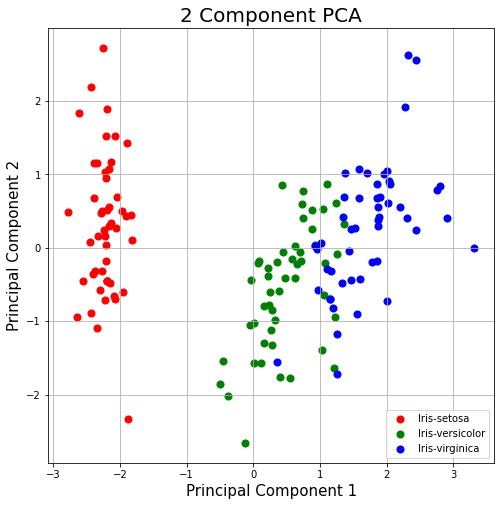

In [77]:
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(1,1,1)
ax.set_xlabel('Principal Component 1',fontsize=15)
ax.set_ylabel('Principal Component 2',fontsize=15)
ax.set_title('2 Component PCA',fontsize=20)
targets=['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
colors=['r','g','b']
for target,color in zip(targets,colors):
    indicesToKeep = pdf['Name'] == target
    ax.scatter(pdf.loc[indicesToKeep,'col1'],pdf.loc[indicesToKeep,'col2'],c=color,s=50)
ax.legend(targets)
ax.grid()

In [33]:
np.random.random?

In [80]:
pdf['Name'] == 'Iris-setosa'

0       True
1       True
2       True
3       True
4       True
       ...  
145    False
146    False
147    False
148    False
149    False
Name: Name, Length: 150, dtype: bool